## This code is to train RC on logistic map and analyse the crisis mechanism

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import networkx as nx
import math

## Building the RC architecture

In [2]:
class ReservoirComputer:
    
    def __init__(self, dim_system, dim_reservoir, rho, sigma):
        
        self.dim_system = dim_system
        self.dim_reservoir = dim_reservoir
        self.r_state = np.zeros(dim_reservoir)                                   
        self.A = generate_adjacency_matrix(dim_reservoir, rho, sigma)

        
        self.W_in = W_inn(dim_reservoir, dim_system)
        self.W_b = W_bb(dim_reservoir)
        self.W_out = np.zeros((dim_system, dim_reservoir))
        
        

    
    def advance_r_state(self, eps, u):
        alpha = 0.86
        self.r_state = ((1- alpha)* self.r_state) + alpha* np.tanh(np.matmul(self.A, self.r_state) + np.matmul(self.W_in, u.T) + self.W_b * (eps - 0.3))             # r_state is updated and stored as r(t+ delta t)
                                                                                    
        return self.r_state

    
    def train(self, trajectory_total, trajectory_new):                                                # Trajectory is the training data (initialized once model is called)
        
    
        R_total = np.empty((self.dim_reservoir, trajectory_total.shape[0]))
        eps_train = [3.92, 3.93, 3.94, 3.95]
        
        div = int((trajectory_total.shape[0])/4)
        
        for m in range(len(eps_train)):

            self.r_state = np.zeros(self.dim_reservoir)
            
            for i in range(div*m , div + div*m):
                
                R_total[:, i] = self.r_state
                u = trajectory_total[i]                                                   
                self.advance_r_state(eps_train[m], u)

        range_removal = [(0,29),(1000,1029),(2000, 2029),(3000, 3029)]
        column_removal = []
        for start, end in range_removal:
            column_removal.extend(range(start, end + 1))
        
        # Remove the specified columns
        R_total = np.delete(R_total, column_removal, axis=1)  #removing the r_state transient (first 10 elements)         
        
        self.W_out = linear_regression(R_total, trajectory_new)

        #print(self.W_out)                  

    def v(self):
        return np.transpose(np.matmul(self.W_out, self.r_state))                   # Gives the predicted output


    def predict(self, eps_new, steps, test_trajectory, train_trajectory):
        
        prediction = np.zeros((steps, self.dim_system))
        prediction[0] = test_trajectory[0,:]

        warmup = train_trajectory[0:30, :]                       # warmup of reservoir

        self.r_state = np.zeros(self.dim_reservoir)

        for l in range(30):

            self.advance_r_state(eps_new, warmup[l])

        self.r_warmup = self.r_state
        
        for i in range(steps-1):
            
            self.advance_r_state(eps_new, prediction[i])
            v = self.v()
            prediction[i+1] = v
            
        return prediction

    def get_weights(self):
        return self.A, self.W_in, self.W_out, self.W_b, self.r_warmup

In [3]:
def W_bb(dim_reservoir):

    np.random.seed(36)

    W_b = (2 * np.random.rand(dim_reservoir) - 1)* 1.15 

    return W_b


def W_inn(dim_reservoir, dim_system):

    np.random.seed(85)
    W_in = 2 * 2.13 * (np.random.rand(dim_reservoir, dim_system) - 0.5)

    return W_in

def generate_adjacency_matrix(dim_reservoir, rho, sigma):
    
    graph = nx.gnp_random_graph(dim_reservoir, sigma, seed = 47)                           # Generates an Erdos-Renyi graph of nodes = dim_reservoir and probab of node connection = sigma
    
    np.random.seed(27)
    nx.set_edge_attributes(graph, {e: {'weight': np.random.uniform(0, 1)} for e in graph.edges})    
    graph = nx.to_numpy_array(graph)

    rescaled = graph
    return scale_matrix(rescaled, rho)


def scale_matrix(A, rho):
    eigenvalues, _ = np.linalg.eig(A)
    max_eigenvalue = np.amax(eigenvalues)
    A = (A/np.absolute(max_eigenvalue)) * rho                 #this makes the spectral radius of matrix A as rho
    return A


In [4]:
def linear_regression(R, trajectory, beta=0.000001):
    Rt = np.transpose(R)
    inverse_part = np.linalg.inv(np.matmul(R, Rt) + beta * np.identity(R.shape[0]))               
    return np.matmul(np.matmul(trajectory.T, Rt), inverse_part)                          

## Generating training data from logistic map

In [5]:
timesteps = 1100     #train for 1000 timesteps and remove 100 as transient

mu_list = [3.92, 3.93, 3.94, 3.95, 3.99]      

data_list = []

for mu in mu_list:
    x0 = 0.3
    for j in range(timesteps):

        x0 = mu*x0*(1-x0)
   
        data_list.append(x0)
   
stacked_total = np.transpose(np.vstack(data_list))                                          
#print(stacked_total.shape)

In [6]:
#train-test split

stacked_train = stacked_total[:, :-1100]
stacked_test = stacked_total[:, -1100:]
stacked_test = stacked_test[:, :1000]        # no sense of removing transient in this case

#print(stacked_train.shape)
# removing transient of first 100 points each time
ranges_to_remove = [(0, 99), (1100, 1199), (2200, 2299), (3300,3399)]
columns_to_remove = []
for start, end in ranges_to_remove:
    columns_to_remove.extend(range(start, end + 1))


stacked_x_modified = np.delete(stacked_train, columns_to_remove, axis=1)
                 
training_data = np.transpose(stacked_x_modified)                # shape of training_data is 

#print(training_data.shape)

# Remove the reservoir transient, 30 points each time
range_to_remove = [(0,29),(1000,1029),(2000, 2029),(3000, 3029)]

column_to_remove = []
for start, end in range_to_remove:
    column_to_remove.extend(range(start, end + 1))

# Remove the specified columns
train_without_transient = np.transpose(np.delete(stacked_x_modified, column_to_remove, axis=1))            
#print(train_without_transient.shape)
valid_data = np.transpose(stacked_test)        

## Checking for the RC predictions

In [7]:
dim_reservoir = 400                                    
model = ReservoirComputer(1, dim_reservoir, 0.9, 0.526)                       #1.47, 0.526

model.train(training_data, train_without_transient)
predicted_data = model.predict(3.99 ,len(valid_data), valid_data, train_without_transient)       

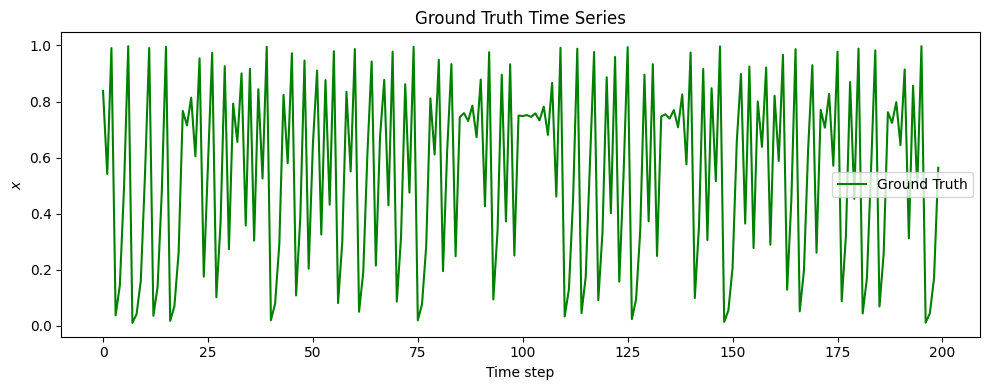

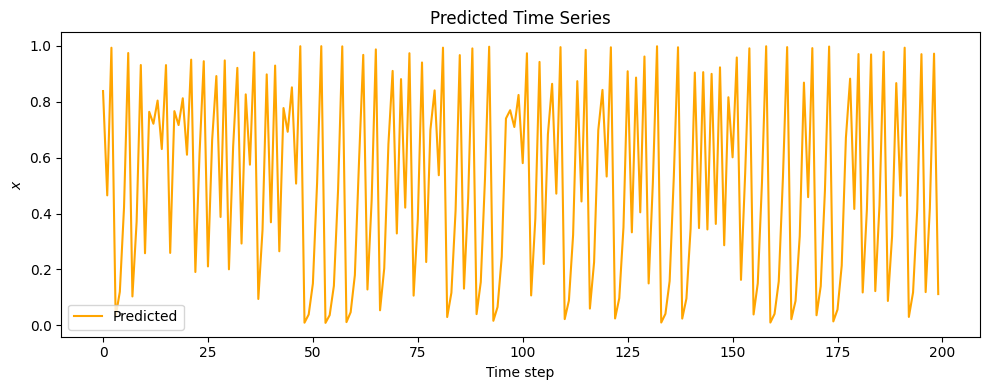

In [10]:
#checking the plots
x_data = valid_data[:,0]

x_pred = predicted_data[:,0]

timeaxis = np.arange(0, (valid_data.shape[0]), 1)
# Plot data on each subplot
h = 200
l = 200
plt.figure(figsize=(10,4))
plt.plot(timeaxis[:h], x_data[:h], color='green', label='Ground Truth')
plt.xlabel("Time step")
plt.ylabel(r"$x$")
plt.title("Ground Truth Time Series")

plt.show()

plt.figure(figsize=(10,4))
plt.plot(timeaxis[:l], x_pred[:l], color='orange', label='Predicted')
plt.xlabel("Time step")
plt.ylabel(r"$x$")
plt.title("Predicted Time Series")
plt.show()

## Directional fibers to find out fixed points

In [11]:
import numpy as np
import sys
import matplotlib.pyplot as plt
import dfibers.solvers as sv
import dfibers.fixed_points as fx
import dfibers.traversal as tv
import dfibers.numerical_utilities as nu                                #this particular .py file might need slight modification locally to support the new python and numpy version (def solve needs to be changed)
import dfibers.logging_utilities as lu

# Load model weights
A, W_in, W_out, W_b, rstate_initial = model.get_weights()

Lambda = A + np.matmul(W_in, W_out)
Omega = W_b
alpha = 0.86
N = Lambda.shape[0]

# Fixed-point detection grid (coarse steps)
bif_params_fp = np.arange(3.0, 4.1, 0.025)                                                     

# Bifurcation plot grid (fine steps)
bif_params_plot = np.arange(3.0, 4.1, 0.001)

# Storage for fixed points across bifurcation parameters
all_bif_fixed_points = []
all_bif_fixed_points_proj = []

# Function definitions
def f(V, bif_param):
    return -V + (1 - alpha) * V + alpha * np.tanh(Lambda @ V + Omega[:, None] * (bif_param - 0.3))
    
def Df(V, bif_param):
    N, P = V.shape
    gamma = Lambda @ V + Omega[:, None]*(bif_param - 0.3)
    sech2 = 1 - np.tanh(gamma)**2
    DfV = np.zeros((P, N, N))
    for p in range(P):
        D = np.diag(sech2[:, p])
        DfV[p,:,:] = alpha * (D @ Lambda - np.eye(N))
    return DfV



def ef(V):
    N, P = V.shape
    return 1e-10 * np.ones((N, P))

terminate = lambda trace: np.any(np.abs(trace.x[:N,:]) > 100)
compute_step_amount = lambda trace: (0.001, None, False)

# Duplicates check
duplicates = lambda V, v: (np.abs(V - v) < 1e-5).all(axis=0)

# Holds previous bif_param fixed points
fxpts_prev = []

# Loop over coarse bifurcation parameters
for bif_param in bif_params_fp:
    
    print(f"\nFinding fixed points for bif_param = {bif_param}")

    num_trials = 15
    all_fxpts_this_param = []

    for trial in range(num_trials):

        # Determine initial guess
        if fxpts_prev and trial < len(fxpts_prev):                                                   #if fxpts_prev < len() returns false if list empty, this is way of writing if the list is non empty and trial<len() holds true
            # Use fixed point from previous bif_param run, plus slight perturbation
            v0 = fxpts_prev[trial] + 0.001 * np.random.randn(N, 1)
            
        else:
            v0 = np.random.uniform(-1, 1, size=(N,1))
            

        # Random fiber direction
        c = np.random.randn(N,1)
        c /= np.linalg.norm(c)

        solution = sv.fiber_solver(
            f = lambda V: f(V, bif_param),
            ef = ef,
            Df = lambda V: Df(V, bif_param),
            v = v0,
            c = c,
            terminate = terminate,
            compute_step_amount = compute_step_amount,
            max_traverse_steps = 2000,
            max_solve_iterations = 32,
            logger = None,
        )

        fxpts = solution["Fixed points"]
        
        if fxpts.shape[1] > 0:
            # Sanitize the fixed points from this trial
            sanitized = fx.sanitize_points(
                fxpts,
                f = lambda V: f(V, bif_param),
                ef = ef,
                Df = lambda V: Df(V, bif_param),
                duplicates = duplicates
            )
            if sanitized.shape[1] > 0:
                all_fxpts_this_param.append(sanitized)
            else:
                print(f"  Trial {trial}: all fixed points eliminated during sanitization.")                  #in the above step, duplicates are removed and points with high residue are also removed
        else:
            print(f"  Trial {trial}: No fixed points found.")

    # Combine sanitized points from all trials
    if all_fxpts_this_param:
        fxpts_all = np.hstack(all_fxpts_this_param)

        # Final deduplication
        fxpts_all = fx.sanitize_points(
            fxpts_all,
            f = lambda V: f(V, bif_param),
            ef = ef,
            Df = lambda V: Df(V, bif_param),
            duplicates = duplicates
        )
        

        if fxpts_all.shape[1] > 0:
            print(f"Found {fxpts_all.shape[1]} unique fixed points at bif_param={bif_param}")
        
            stabilities = []  # True = stable, False = unstable
        
            # Print residuals and eigenvalues for stability analysis
            for i in range(fxpts_all.shape[1]):
                v_fp = fxpts_all[:, [i]]
                
                # Residual
                residual = np.linalg.norm(f(v_fp, bif_param))
                print(f"  FP {i}: residual = {residual:.3e}")
                
                # Jacobian at this fixed point
                J = Df(v_fp, bif_param)[0,:,:] + np.eye(v_fp.shape[0])                    #correct jacobian form
                
                # Eigenvalues
                eigvals = np.linalg.eigvals(J)
                max_abs = np.max(np.abs(eigvals))
                print(f"      max |eigenvalue| = {max_abs:.6f}")
        
                stabilities.append(max_abs <= 1.0)  # Stable if all eigenvalues <= 1 in magnitude
        
            # Project fixed points to output space
    
  

            projections = W_out @ fxpts_all
            all_bif_fixed_points.append(fxpts_all)
            all_bif_fixed_points_proj.append((bif_param, projections, stabilities))
        
            print(projections)
            
            # Save these fixed points as seeds for next bif_param
            fxpts_prev = [fxpts_all[:, [i]] for i in range(fxpts_all.shape[1])]

        else:
            print(f"No unique fixed points survived final sanitization at bif_param={bif_param}")
            fxpts_prev = []
    else:
        print(f"No fixed points found at bif_param={bif_param}")
        fxpts_prev = []


Finding fixed points for bif_param = 3.0
  Trial 4: all fixed points eliminated during sanitization.
  Trial 13: all fixed points eliminated during sanitization.
Found 3 unique fixed points at bif_param=3.0
  FP 0: residual = 1.245e-12
      max |eigenvalue| = 0.158245
  FP 1: residual = 5.887e-15
      max |eigenvalue| = 0.175548
  FP 2: residual = 2.728e-14
      max |eigenvalue| = 3.423439
[[ 16.88567787 -14.84176832  -0.02726609]]

Finding fixed points for bif_param = 3.025
  Trial 10: all fixed points eliminated during sanitization.
Found 3 unique fixed points at bif_param=3.025
  FP 0: residual = 1.422e-10
      max |eigenvalue| = 0.158321
  FP 1: residual = 1.583e-11
      max |eigenvalue| = 0.176121
  FP 2: residual = 2.092e-14
      max |eigenvalue| = 3.425451
[[ 16.90306164 -14.83604784  -0.02509565]]

Finding fixed points for bif_param = 3.05
Found 4 unique fixed points at bif_param=3.05
  FP 0: residual = 6.588e-11
      max |eigenvalue| = 0.158399
  FP 1: residual = 4.718

## RC bifurcation plot

In [12]:
# Two bifurcation parameter ranges with different step sizes
bif_params_low = np.arange(3.0, 3.5, 0.008)     # coarse
bif_params_high = np.arange(3.5, 4.1, 0.0008)   # fine

# Concatenate them
bif_params_plot = np.concatenate([bif_params_low, bif_params_high])

timestepss = 600
broadcast_shape = 30

bif_repeated = np.repeat(bif_params_plot, broadcast_shape)
bif_broadcasted = bif_repeated.reshape(len(bif_params_plot), broadcast_shape)

x_list = np.empty((1, timestepss))
x_listfinal = np.empty((len(bif_params_plot), broadcast_shape))

for k, bif_param in enumerate(bif_params_plot):
    rstate0 = rstate_initial.copy()
    for j in range(timestepss):
        r = (1-alpha)*rstate0 + alpha*np.tanh(np.matmul(Lambda, rstate0) + Omega*(bif_param - 0.3))
        rstate0 = r
        x_list[:, j] = np.matmul(W_out, r)                                 #Projecting back to 1-D

    x_listfinal[k, :] = x_list[:, -broadcast_shape:]
    x_listfinal[k, :] = x_list[:, -broadcast_shape:]


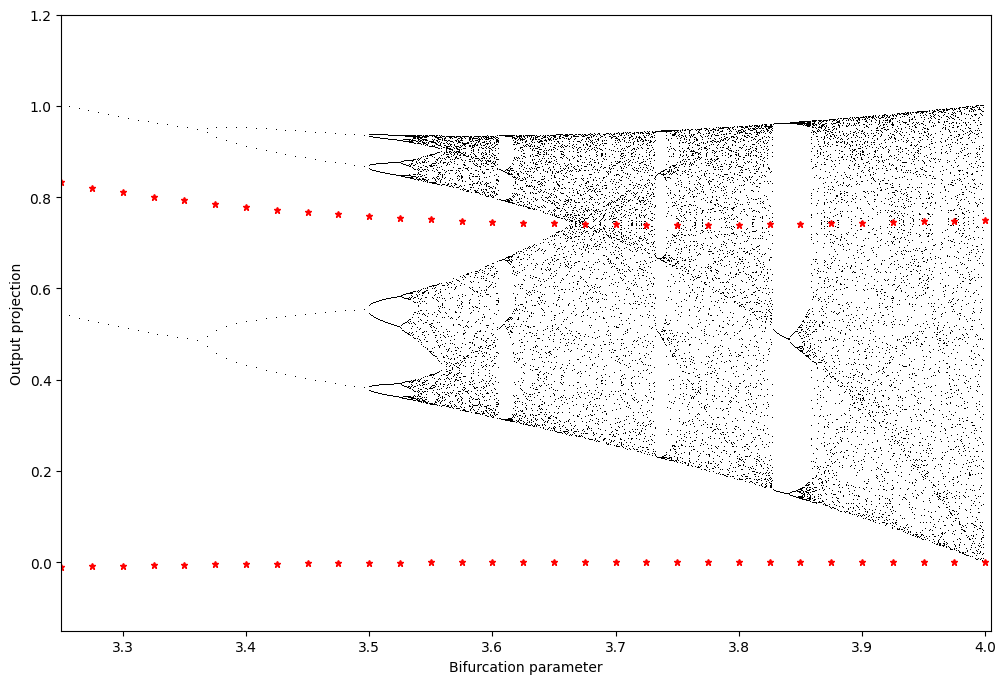

In [13]:
plt.figure(figsize=(12, 8))

# Plot the bifurcation points
for i in range(len(bif_params_plot)):
    plt.plot(
        bif_broadcasted[i, :],
        x_listfinal[i, :],
        color='black',
        ls='',
        marker=','
    )

# Plot fixed-point projections with stability-based colors
for bif_param, projections, stabilities in all_bif_fixed_points_proj:
    for j in range(projections.shape[1]):
        color = 'blue' if stabilities[j] else 'red'
        plt.plot(
            bif_param,
            projections[0, j],  # projections is 2D: (output_dim, num_points)
            marker='*',
            markersize=5,
            color=color,
            label=(
                "Stable FP" if (color == 'blue' and bif_param == bif_params_fp[0]) else
                "Unstable FP" if (color == 'red' and bif_param == bif_params_fp[0]) else
                None
            )
        )

plt.xlabel("Bifurcation parameter")
plt.ylabel("Output projection")

plt.xlim(3.25, 4.005)
plt.ylim(-0.15, 1.2)                    #For better clarity and to see only the relevant fixed points

plt.show()

## Computation of scaling exponent of trained RC

In [14]:
bif_array = np.array([3.999,  4.0001, 4.0005, 4.001, 4.005, 4.01, 4.05, 4.1 ])
# Parameters
timesteps = 200000
alpha = 0.86
num_trials = 10000
threshold = 0             # Collapse threshold
exit_threshold = 1.5         # Divergence threshold

# Initialize scaling list
scaling_list_avg = []

# Get model weights
A, W_in, W_out, W_b, rstate_initial = model.get_weights()
Lambda = A + np.matmul(W_in, W_out)
Omega = W_b


# Simulation function
def simulate_single_perturb(bif_param):
    r_sstate = np.zeros(400)

    # Generate chaotic warmup input from logistic map
    x0_list = []
    x0 = np.random.uniform(0.2, 0.6)
    for _ in range(300):
        x0 = 3.99 * x0 * (1 - x0)
        x0_list.append(x0)

    x0_array = np.array(x0_list).reshape(300, 1)
    warmup_array = x0_array[-101:]  # Shape: (41, 1)

    # Warmup phase
    for l in range(100):
        rstate_initial1 = (1 - alpha) * r_sstate + alpha * np.tanh(
            np.matmul(A, r_sstate) +
            np.matmul(W_in, warmup_array[l, :].T) +
            W_b * (bif_param - 0.3)
        )
        r_sstate = rstate_initial1

    preddd_data = warmup_array[-1, :]

    # Simulation loop
    for k in range(timesteps):
        r = (1 - alpha) * rstate_initial1 + alpha * np.tanh(
            np.matmul(A, rstate_initial1) +
            np.matmul(W_in, preddd_data) +
            Omega * (bif_param - 0.3)
        )
        rstate_initial1 = r
        preddd_data = np.matmul(W_out, r)

        val = preddd_data.item()  # Convert to scalar

        if val < threshold:
            return k              # Collapse
        elif val > exit_threshold:
            return None           # Divergence

    return None              # No collapse or divergence

from tqdm import tqdm
# Main loop
for i, bif_param in enumerate(bif_array):
    print(f"\nRunning for bif_param = {bif_param:.5f} ({i + 1}/{len(bif_array)})...")
    results = []

    for _ in tqdm(range(num_trials), desc=f"Trials for bif={bif_param:.5f}"):
        result = simulate_single_perturb(bif_param)
        if result is not None:
            results.append(result)

    skipped = num_trials - len(results)

    if results:
        avg = np.mean(results)
    else:
        avg = float('nan')

    scaling_list_avg.append(avg)

    print(f"  Average time to collapse (valid trials = {len(results)}): {avg:.2f}")
    print(f"  Skipped {skipped} divergent trials")



Running for bif_param = 3.99900 (1/8)...


Trials for bif=3.99900: 100%|█████████████| 10000/10000 [01:59<00:00, 83.97it/s]


  Average time to collapse (valid trials = 10000): 139.03
  Skipped 0 divergent trials

Running for bif_param = 4.00010 (2/8)...


Trials for bif=4.00010: 100%|████████████| 10000/10000 [01:28<00:00, 112.72it/s]


  Average time to collapse (valid trials = 10000): 72.09
  Skipped 0 divergent trials

Running for bif_param = 4.00050 (3/8)...


Trials for bif=4.00050: 100%|████████████| 10000/10000 [01:18<00:00, 127.38it/s]


... (7 outputs left out)

Trials for bif=4.05000: 100%|████████████| 10000/10000 [00:55<00:00, 181.81it/s]


  Average time to collapse (valid trials = 10000): 11.22
  Skipped 0 divergent trials

Running for bif_param = 4.10000 (8/8)...


Trials for bif=4.10000: 100%|████████████| 10000/10000 [00:57<00:00, 173.03it/s]

  Average time to collapse (valid trials = 10000): 7.68
  Skipped 0 divergent trials


Estimated scaling exponent γ ≈ 0.535


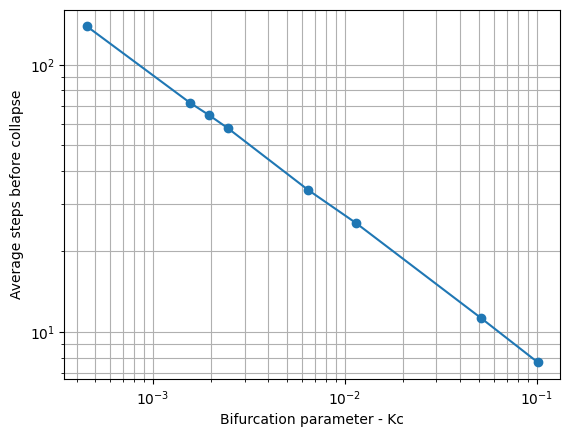

In [16]:
bif_array_shift = bif_array - 3.998548                                  

log_x = np.log(bif_array_shift)
log_y = np.log(scaling_list_avg)
slope, _ = np.polyfit(log_x, log_y, 1)
print(f"Estimated scaling exponent γ ≈ {-slope:.3f}")

# Plot
plt.loglog(bif_array_shift, scaling_list_avg, marker='o', linestyle='-')
plt.xlabel("Bifurcation parameter - Kc")
plt.ylabel("Average steps before collapse")
plt.grid(True, which='both')
plt.show()